# 인공신경망(ANN) 분류 실습 - 보안 사고 "고비용 여부" 예측

**목표:** 보안 사고 한 건의 정보(공격 유형, 산업군, 감염 호스트 수, 탐지 시간 등)를 보고, 그 사고가 **고비용 사고(대응 비용 \$100K 이상)인지 아닌지**를 맞히는 **분류(Classification)** 모델을 만듭니다.

`ann_security_ko.ipynb`(회귀)와 무엇이 다른가요?

| 구분 | 회귀 (ann_security_ko) | 분류 (이 노트북) |
|---|---|---|
| 정답 열 | `response_cost_k` (금액) | `cost_class` (0 = 저비용, 1 = 고비용) |
| 출력 크기 | 1 (숫자 하나) | 2 (클래스별 점수) |
| 손실 함수 | `MSELoss` → RMSE | `CrossEntropyLoss` |
| 평가 지표 | RMSE (천 달러) | 정확도, 혼동 행렬 |
| 저장 파일 | `SecurityCostRegrModel.pt` | `SecurityCostClassModel.pt` |

마지막 단계에서는 예측 결과를 **로컬 LLM(Ollama)** 에 넘겨 한국어 사고 보고서를 쓰게 합니다. 1_1 실습에서 배운 OpenAI 호출 방식을 그대로 활용합니다.

## 1단계: 필요한 라이브러리 불러오기
회귀 실습과 같습니다.

In [1]:
import os
# CPU에서 학습합니다. 이 설정은 반드시 torch를 import 하기 "전에" 실행해야 효과가 있습니다.
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '-1')

import torch                # PyTorch 기본 라이브러리
import torch.nn as nn       # 신경망 층과 손실 함수

import numpy as np          # 수치 계산용 배열 라이브러리
import pandas as pd         # 표(DataFrame) 형태의 데이터 처리 라이브러리
import matplotlib.pyplot as plt   # 그래프 그리기 라이브러리
%matplotlib inline

## 2단계: 데이터 불러오기와 정답 확인
이번 정답은 `cost_class` 입니다. 데이터를 만든 기준은 다음과 같습니다.
* `cost_class = 0` : 대응 비용 \$100K 미만 (저비용)
* `cost_class = 1` : 대응 비용 \$100K 이상 (고비용)

In [2]:
df = pd.read_csv('./data/SecurityIncidents.csv')
df.head()

,detected_datetime,response_cost_k,cost_class,attack_type,industry,src_latitude,src_longitude,dst_latitude,dst_longitude,hosts_affected,data_exfil_gb,time_to_detect_hrs,cvss_score,employees
0,2024-03-06 11:58:35 UTC,74.70,0,Malware,Technology,40.044233,117.991181,0.914661,104.244946,26,0.76,7.8,4.7,2445
1,2024-03-25 16:05:54 UTC,35.48,0,Phishing,Retail,40.031545,127.817074,43.511939,-79.114732,2,0.12,32.2,6.7,2005
2,2024-03-22 07:52:19 UTC,160.65,1,DDoS,Manufacturing,37.603389,50.816497,43.136998,-79.661414,30,0.01,21.5,8.1,62
3,2024-03-16 06:55:34 UTC,218.89,1,Malware,Healthcare,2.467286,102.373496,-33.941897,151.236021,24,1.66,65.1,6.2,306
4,2024-03-16 02:59:10 UTC,426.87,1,Ransomware,Government,39.682988,116.338039,-33.574722,151.128360,34,0.05,6.7,8.5,1234


In [3]:
# 클래스별 개수: 한쪽으로 크게 치우쳐 있지 않은지 확인합니다.
df['cost_class'].value_counts()

cost_class
0    31834
1    28166
Name: count, dtype: int64

In [4]:
# 정말 $100K가 기준인지 클래스별 비용 범위로 확인
df.groupby('cost_class')['response_cost_k'].agg(['min', 'max', 'mean'])

,min,max,mean
cost_class,,,
0,10.37,99.99,55.522143
1,100.00,600.00,197.052861


0과 1이 대략 53 : 47로 고르게 나뉘어 있습니다.
그래서 **"무조건 0이라고 찍는" 모델의 정확도는 약 53%** 입니다. 우리 모델은 이보다 훨씬 높아야 의미가 있습니다.

> ⚠️ `response_cost_k`는 정답을 그대로 알려 주는 열이므로 **입력에 넣으면 안 됩니다.** (시험지에 답을 적어 주는 것과 같습니다.)

## 3단계: 특성 만들기 (공격 거리, 현지 시각)
회귀 실습의 3·4단계와 똑같은 전처리입니다.

In [5]:
def haversine_distance(df, lat1, long1, lat2, long2):
    """두 GPS 좌표 쌍 사이의 하버사인 거리(km)"""
    r = 6371
    phi1 = np.radians(df[lat1])
    phi2 = np.radians(df[lat2])
    delta_phi = np.radians(df[lat2]-df[lat1])
    delta_lambda = np.radians(df[long2]-df[long1])
    a = np.sin(delta_phi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    return r * c

# 공격 출발지 → 피해지 거리
df['dist_km'] = haversine_distance(df, 'src_latitude', 'src_longitude', 'dst_latitude', 'dst_longitude')

# 피해지 경도로 현지 시각을 근사하고 시/오전오후/요일을 뽑습니다.
tz_offset = pd.to_timedelta((df['dst_longitude'] / 15).round(), unit='h')
df['LocalDate'] = pd.to_datetime(df['detected_datetime'].str[:19]) + tz_offset
df['Hour'] = df['LocalDate'].dt.hour
df['AMorPM'] = np.where(df['Hour']<12, 'am', 'pm')
df['Weekday'] = df['LocalDate'].dt.strftime("%a")
df.head()

,detected_datetime,response_cost_k,cost_class,attack_type,industry,src_latitude,src_longitude,dst_latitude,dst_longitude,hosts_affected,data_exfil_gb,time_to_detect_hrs,cvss_score,employees,dist_km,LocalDate,Hour,AMorPM,Weekday
0,2024-03-06 11:58:35 UTC,74.70,0,Malware,Technology,40.044233,117.991181,0.914661,104.244946,26,0.76,7.8,4.7,2445,4567.851627,2024-03-06 18:58:35,18,pm,Wed
1,2024-03-25 16:05:54 UTC,35.48,0,Phishing,Retail,40.031545,127.817074,43.511939,-79.114732,2,0.12,32.2,6.7,2005,10340.417045,2024-03-25 11:05:54,11,am,Mon
2,2024-03-22 07:52:19 UTC,160.65,1,DDoS,Manufacturing,37.603389,50.816497,43.136998,-79.661414,30,0.01,21.5,8.1,62,9740.368317,2024-03-22 02:52:19,2,am,Fri
3,2024-03-16 06:55:34 UTC,218.89,1,Malware,Healthcare,2.467286,102.373496,-33.941897,151.236021,24,1.66,65.1,6.2,306,6514.395356,2024-03-16 16:55:34,16,pm,Sat
4,2024-03-16 02:59:10 UTC,426.87,1,Ransomware,Government,39.682988,116.338039,-33.574722,151.128360,34,0.05,6.7,8.5,1234,8896.869793,2024-03-16 12:59:10,12,pm,Sat


## 4단계: 범주형 / 연속형 / 정답 열 나누기
입력 열은 회귀와 같고, **정답 열만 `cost_class`로 바뀝니다.**

In [6]:
cat_cols = ['Hour', 'AMorPM', 'Weekday', 'attack_type', 'industry']
cont_cols = ['src_latitude', 'src_longitude', 'dst_latitude', 'dst_longitude', 'hosts_affected',
             'data_exfil_gb', 'time_to_detect_hrs', 'cvss_score', 'employees', 'dist_km']
y_col = ['cost_class']   # ← 회귀와 다른 부분

## 5단계: 텐서로 변환하기
분류에서 가장 중요한 차이가 여기 있습니다.

* 회귀의 정답: `float` 텐서, 모양 `(60000, 1)`
* 분류의 정답: **`int64`(long) 텐서, 모양 `(60000,)`** — `CrossEntropyLoss`는 정답으로 **클래스 번호(0, 1)** 를 1차원으로 받습니다.

In [7]:
for cat in cat_cols:
    df[cat] = df[cat].astype('category')

cats = np.stack([df[col].cat.codes.values for col in cat_cols], 1)
cats = torch.tensor(cats, dtype=torch.int64)

conts = np.stack([df[col].values for col in cont_cols], 1)
conts = torch.tensor(conts, dtype=torch.float)

# 분류 정답: 정수(long) + 1차원
y = torch.tensor(df[y_col].values, dtype=torch.int64).flatten()

cats.shape, conts.shape, y.shape

(torch.Size([60000, 5]), torch.Size([60000, 10]), torch.Size([60000]))

## 6단계: 임베딩 크기 정하기

In [8]:
cat_szs = [len(df[col].cat.categories) for col in cat_cols]
emb_szs = [(size, min(50, (size+1)//2)) for size in cat_szs]
emb_szs

[(24, 12), (2, 1), (7, 4), (8, 4), (7, 4)]

## 7단계: TabularModel 정의하기
회귀 실습과 **완전히 같은 클래스**입니다. 모델을 만들 때 `out_sz`만 **2**(클래스 개수)로 넘기면 분류 모델이 됩니다.
출력층은 활성화 함수 없이 두 클래스의 **점수(logit)** 를 내보내고, 확률로 바꾸는 softmax는 `CrossEntropyLoss` 안에서 처리됩니다.

In [9]:
class TabularModel(nn.Module):

    def __init__(self, emb_szs, n_cont, out_sz, layers, p=0.5):
        super().__init__()
        self.embeds = nn.ModuleList([nn.Embedding(ni, nf) for ni,nf in emb_szs])
        self.emb_drop = nn.Dropout(p)
        self.bn_cont = nn.BatchNorm1d(n_cont)

        layerlist = []
        n_emb = sum((nf for ni,nf in emb_szs))
        n_in = n_emb + n_cont
        for i in layers:
            layerlist.append(nn.Linear(n_in,i))
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i
        layerlist.append(nn.Linear(layers[-1],out_sz))   # 분류: out_sz = 클래스 개수
        self.layers = nn.Sequential(*layerlist)

    def forward(self, x_cat, x_cont):
        embeddings = []
        for i,e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:,i]))
        x = torch.cat(embeddings, 1)
        x = self.emb_drop(x)
        x_cont = self.bn_cont(x_cont)
        x = torch.cat([x, x_cont], 1)
        return self.layers(x)

In [10]:
torch.manual_seed(33)

# 출력 2개 (0 = 저비용, 1 = 고비용)
model = TabularModel(emb_szs, conts.shape[1], 2, [200,100], p=0.4)
model

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(24, 12)
    (1): Embedding(2, 1)
    (2): Embedding(7, 4)
    (3): Embedding(8, 4)
    (4): Embedding(7, 4)
  )
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=35, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=2, bias=True)
  )
)

## 8단계: 손실 함수와 옵티마이저
* **`CrossEntropyLoss`**: 모델이 정답 클래스에 높은 확률을 줄수록 작아지는 손실입니다.
* 옵티마이저는 회귀와 같은 Adam(lr=0.001)을 씁니다.

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 9단계: 학습용 / 테스트용 나누기 (80% / 20%)

In [12]:
batch_size = 60000
test_size = int(batch_size * .2)

cat_train = cats[:batch_size-test_size]
cat_test  = cats[batch_size-test_size:batch_size]
con_train = conts[:batch_size-test_size]
con_test  = conts[batch_size-test_size:batch_size]
y_train   = y[:batch_size-test_size]
y_test    = y[batch_size-test_size:batch_size]

len(cat_train), len(cat_test)

(48000, 12000)

## 10단계: 모델 학습시키기
반복 구조는 회귀와 같고, 손실 계산만 `CrossEntropyLoss`로 바뀝니다. 학습 정확도도 함께 기록합니다.

In [13]:
import time
start_time = time.time()

epochs = 300
losses = []
train_accs = []

for i in range(epochs):
    i += 1
    y_pred = model(cat_train, con_train)        # (48000, 2) 점수
    loss = criterion(y_pred, y_train)           # 정답 클래스 번호와 비교
    losses.append(loss.item())

    # 점수가 더 큰 쪽을 예측 클래스로 보고 정확도 계산
    acc = (y_pred.argmax(1) == y_train).float().mean().item()
    train_accs.append(acc)

    if i%25 == 1:
        print(f'epoch: {i:3}  loss: {loss.item():.6f}  train acc: {acc*100:6.2f}%')

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f'epoch: {i:3}  loss: {loss.item():.6f}  train acc: {acc*100:6.2f}%')
print(f'\nDuration: {time.time() - start_time:.0f} seconds')

epoch:   1  loss: 0.884720  train acc:  46.73%


epoch:  26  loss: 0.461256  train acc:  78.07%


epoch:  51  loss: 0.408791  train acc:  80.77%


epoch:  76  loss: 0.379589  train acc:  82.40%


epoch: 101  loss: 0.360648  train acc:  83.35%


...

epoch: 201  loss: 0.308091  train acc:  86.13%


epoch: 226  loss: 0.294612  train acc:  86.97%


epoch: 251  loss: 0.284814  train acc:  87.22%


epoch: 276  loss: 0.276022  train acc:  87.90%


epoch: 300  loss: 0.267500  train acc:  88.16%

Duration: 153 seconds


## 11단계: 손실 / 정확도 그래프

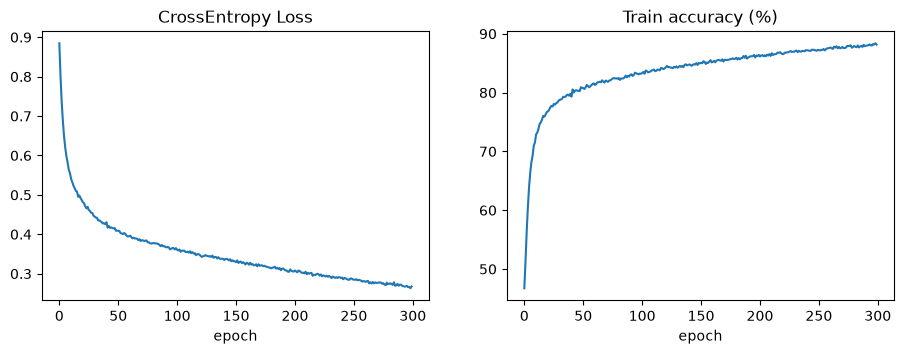

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(range(epochs), losses)
ax[0].set_title('CrossEntropy Loss'); ax[0].set_xlabel('epoch')
ax[1].plot(range(epochs), [a*100 for a in train_accs])
ax[1].set_title('Train accuracy (%)'); ax[1].set_xlabel('epoch');

## 12단계: 테스트 데이터로 평가하기
* **정확도(Accuracy)**: 전체 중 맞힌 비율
* **혼동 행렬(Confusion Matrix)**: 실제 클래스와 예측 클래스를 표로 정리한 것입니다. 보안 실무에서는 특히 **고비용 사고를 저비용으로 잘못 본 경우(놓친 경우)** 가 위험합니다.

In [15]:
model.eval()
with torch.no_grad():
    y_val = model(cat_test, con_test)
    test_loss = criterion(y_val, y_test)

y_hat = y_val.argmax(1)
correct = (y_hat == y_test).sum().item()
print(f'Test loss: {test_loss.item():.6f}')
print(f'{correct} out of {len(y_test)} = {100*correct/len(y_test):.2f}% correct')
print(f'(항상 0으로 찍었을 때의 정확도: {100*(y_test==0).float().mean().item():.2f}%)')

Test loss: 0.197524
11058 out of 12000 = 92.15% correct
(항상 0으로 찍었을 때의 정확도: 53.47%)


In [16]:
# 혼동 행렬: 행 = 실제, 열 = 예측
cm = pd.crosstab(pd.Series(y_test.numpy(), name='실제'),
                 pd.Series(y_hat.numpy(), name='예측'))
cm.index = ['저비용(0)', '고비용(1)']
cm.columns = ['저비용(0)', '고비용(1)']
cm

,저비용(0),고비용(1)
저비용(0),5846,571
고비용(1),371,5212


In [17]:
tn, fp, fn, tp = cm.values.ravel()
precision = tp / (tp + fp)   # 고비용이라고 예측한 것 중 진짜 고비용 비율
recall    = tp / (tp + fn)   # 진짜 고비용 사고 중 모델이 잡아낸 비율
print(f'정밀도(Precision): {precision*100:.2f}%')
print(f'재현율(Recall)   : {recall*100:.2f}%   ← 고비용 사고를 놓치지 않는 능력')
print(f'놓친 고비용 사고 : {fn}건')

정밀도(Precision): 90.13%
재현율(Recall)   : 93.35%   ← 고비용 사고를 놓치지 않는 능력
놓친 고비용 사고 : 371건


처음 20개 테스트 데이터의 예측 확률을 살펴봅니다. `softmax`로 점수를 확률로 바꿉니다.

In [18]:
probs = torch.softmax(y_val, dim=1)[:, 1]   # 고비용일 확률
print(f'{"P(고비용)":>10} {"예측":>4} {"실제":>4} {"실제비용($K)":>12}')
costs = df['response_cost_k'].values[batch_size-test_size:]
for i in range(20):
    mark = '' if y_hat[i] == y_test[i] else '  ✗'
    print(f'{i+1:2}. {probs[i].item():7.3f} {y_hat[i].item():5} {y_test[i].item():5} {costs[i]:12.2f}{mark}')

    P(고비용)   예측   실제     실제비용($K)
 1.   0.425     0     0        89.41
 2.   0.425     0     0        70.97
 3.   0.035     0     0        39.90
 4.   0.157     0     0        46.14
 5.   0.998     1     1       432.61
 6.   0.946     1     1       180.97
 7.   0.963     1     1       200.79
 8.   0.691     1     1       110.65
 9.   0.970     1     1       182.85
10.   0.994     1     1       221.03
11.   0.278     0     0        71.69
12.   0.014     0     0        32.63
13.   0.011     0     0        51.32
14.   0.033     0     0        29.16
15.   0.883     1     1       132.60
16.   0.708     1     1       116.34
17.   0.008     0     0        30.13
18.   0.999     1     1       312.82
19.   0.006     0     0        36.47
20.   0.992     1     1       280.87


틀린 예측(✗)은 대부분 실제 비용이 경계값 \$100K 근처에 있습니다. 경계에 가까운 사고는 모델도 헷갈려 한다는 뜻입니다.

## 13단계: 모델 저장하기

In [19]:
if len(losses) == epochs:
    torch.save(model.state_dict(), 'SecurityCostClassModel.pt')
    print('저장 완료: SecurityCostClassModel.pt')
else:
    print('Model has not been trained. Consider loading a trained model instead.')

저장 완료: SecurityCostClassModel.pt


## 14단계: 저장된 모델 불러오기
커널을 재시작했다고 가정하고, 필요한 것만 다시 준비합니다. (`TabularModel`, `haversine_distance` 셀을 먼저 실행해 두어야 합니다.)

In [20]:
# pandas가 붙인 범주 코드 순서(알파벳 순)와 같은 목록
weekdays = ['Fri', 'Mon', 'Sat', 'Sun', 'Thu', 'Tue', 'Wed']
attack_types = ['Brute Force', 'DDoS', 'Data Exfiltration', 'Insider Threat',
                'Malware', 'Phishing', 'Ransomware', 'SQL Injection']
industries = ['Education', 'Finance', 'Government', 'Healthcare',
              'Manufacturing', 'Retail', 'Technology']

emb_szs = [(24, 12), (2, 1), (7, 4), (8, 4), (7, 4)]
model2 = TabularModel(emb_szs, 10, 2, [200,100], p=0.4)   # 출력 2개!
model2.load_state_dict(torch.load('SecurityCostClassModel.pt'))
model2.eval()

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(24, 12)
    (1): Embedding(2, 1)
    (2): Embedding(7, 4)
    (3): Embedding(8, 4)
    (4): Embedding(7, 4)
  )
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=35, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=2, bias=True)
  )
)

## 15단계: 새로운 사고의 고비용 확률 예측하기
회귀 노트북의 `test_data`와 전처리는 같고, 결과로 **클래스와 확률**을 돌려줍니다.

In [21]:
def classify_incident(mdl, incident):
    dfx = pd.DataFrame(incident, index=[0])
    dfx['dist_km'] = haversine_distance(dfx, 'src_latitude', 'src_longitude',
                                        'dst_latitude', 'dst_longitude')
    tz_offset = pd.to_timedelta((dfx['dst_longitude'] / 15).round(), unit='h')
    dfx['LocalDate'] = pd.to_datetime(dfx['detected_datetime']) + tz_offset
    dfx['Hour'] = dfx['LocalDate'].dt.hour
    dfx['AMorPM'] = np.where(dfx['Hour']<12, 0, 1)
    dfx['Weekday'] = weekdays.index(dfx['LocalDate'].dt.strftime("%a")[0])
    dfx['attack_type'] = attack_types.index(dfx['attack_type'][0])
    dfx['industry'] = industries.index(dfx['industry'][0])

    xcats = torch.tensor(np.stack([dfx[c].values for c in cat_cols], 1), dtype=torch.int64)
    xconts = torch.tensor(np.stack([dfx[c].values for c in cont_cols], 1), dtype=torch.float)

    with torch.no_grad():
        p_high = torch.softmax(mdl(xcats, xconts), dim=1)[0, 1].item()
    label = '고비용' if p_high >= 0.5 else '저비용'
    print(f'예측: {label} (고비용일 확률 {p_high*100:.1f}%)')
    return label, p_high

In [22]:
# 사례 1: 병원 랜섬웨어 (회귀 노트북과 같은 사례)
ransomware = {'attack_type': 'Ransomware', 'industry': 'Healthcare',
              'src_latitude': 50.45, 'src_longitude': 30.52,
              'dst_latitude': 40.71, 'dst_longitude': -74.01,
              'hosts_affected': 60, 'data_exfil_gb': 5.0, 'time_to_detect_hrs': 48.0,
              'cvss_score': 9.1, 'employees': 5000,
              'detected_datetime': '2024-03-17 02:30:00'}
r1 = classify_incident(model2, ransomware)

# 사례 2: 소규모 IT 회사 피싱
phishing = dict(ransomware, attack_type='Phishing', industry='Technology',
                hosts_affected=2, data_exfil_gb=0.0, time_to_detect_hrs=3.0,
                cvss_score=4.0, employees=200)
r2 = classify_incident(model2, phishing)

예측: 고비용 (고비용일 확률 100.0%)
예측: 저비용 (고비용일 확률 0.1%)


## 16단계 (확장): LLM으로 사고 보고서 자동 작성하기
분류 모델은 "고비용일 확률 몇 %"라는 **숫자**만 알려 줍니다. 이 숫자와 사고 정보를 **LLM**에 넘기면 담당자가 바로 읽을 수 있는 **보고서 문장**으로 바꿔 줍니다.

* 1_1 실습과 같은 `OpenAI` 클라이언트를 쓰되, 주소를 로컬 **Ollama**로 지정합니다.
* Ollama가 실행 중이고 `qwen2.5:3b` 모델을 받아 두어야 합니다. (`ollama pull qwen2.5:3b`)
* OpenAI 크레딧이 있다면 `OpenAI()` + `model="gpt-4.1-mini"`로 바꿔도 됩니다.

In [23]:
from openai import OpenAI

llm = OpenAI(base_url="http://localhost:11434/v1", api_key="ollama")

system_prompt = """
당신은 기업 보안관제센터(SOC)의 보안 분석가입니다.
사고 정보와 비용 예측 결과를 받아, 경영진에게 보낼 짧은 사고 보고서를 작성합니다.
반드시 한국어(한글)로만 답하고, 한자·중국어·영어 문장은 섞지 마세요.
형식: 1) 사고 요약 2) 예상 비용 등급과 근거 3) 즉시 조치 권고 3가지
"""

def write_report(incident, label, p_high):
    user_prompt = f"""
[사고 정보]
{incident}

[ANN 분류 모델 결과]
예측 등급: {label} (고비용일 확률 {p_high*100:.1f}%, 기준: 대응 비용 $100K)
"""
    try:
        response = llm.chat.completions.create(
            model="qwen2.5:3b",
            messages=[{"role": "system", "content": system_prompt},
                      {"role": "user", "content": user_prompt}],
            temperature=0.3,
        )
        print(response.choices[0].message.content)
    except Exception as e:
        print('LLM 호출 실패 - Ollama가 실행 중인지 확인하세요:', e)

In [24]:
write_report(ransomware, *r1)

1) 사고 요약: 
보안 침입 사고는 2024년 3월 17일 오전 2시 30분에 HealthCare 산업의 시스템에서 발생하였습니다. 침입은 Ransomware를 사용하여 60개의 호스트를 악용하였고, 압축된 데이터 5GB를 외부로 유출하였습니다. 침입 사고는 48시간이 지나서야 발견되었습니다.

2) 예상 비용 등급과 근거: 
고비용 등급으로 예측되었습니다. 이는 침입 사고의 크기와 복구 비용, 시간, 그리고 압축된 데이터의 크기에 기반합니다. 압축된 데이터 5GB의 비용은 약 $100K로 추정되며, 복구 비용은 추가로 $100K가 소요될 것으로 예상됩니다. 

3) 즉시 조치 권고: 
1) 모든 시스템을 즉시 백업합니다. 
2) 모든 시스템을 스캔하여 침입 사고의 영향을 확인합니다. 
3) 침입 사고의 영향을 최소화하기 위해 필요한 모든 시스템을 즉시 복구합니다. 
4) 모든 시스템을 최신 보안 패치로 업데이트합니다. 
5) 보안 강화 계획을 수립하고 실행합니다. 
6) 보안 팀을 강화하고, 추가적인 보안 교육을 제공합니다. 
7) 침입 사고에 대한 보고서를 작성하고, 관련 당국에 보고합니다.


In [25]:
write_report(phishing, *r2)

1) 사고 요약: 기술 분야에서 발생한 피싱 공격으로, 2개의 호스트가 감염되어 200명의 직원이 영향을 받았습니다. 공격은 2024년 3월 17일 02시 30분에 감지되었으며, 감염 시간은 3시간이 걸렸습니다. 공격의 CVSS 점수는 4.0으로, 데이터 유출량은 0GB입니다. 공격의 출발지와 도착지의 위도 경도는 각각 50.45, 30.52와 40.71, -74.01입니다.

2) 예상 비용 등급과 근거: 저비용 등급으로 분류되었습니다. 이는 공격의 CVSS 점수(4.0)와 데이터 유출량(0GB)이 낮아, 대응 비용이 $100K 이하로 추정됩니다. 이는 공격의 크기와 속도, 그리고 예상 비용을 고려한 결과입니다.

3) 즉시 조치 권고: 
- 직원 교육: 피싱 공격에 대한 교육을 실시하여 직원들이 피싱 공격에 대한 인식을 높이고, 실제 공격을 방지하도록 합니다.
- 보안 업데이트: 공격으로 인한 호스트의 보안 업데이트를 실시합니다.
- 감염 호스트의 제거: 감염된 호스트를 제거하고, 공격자가 사용한 도구와 기술을 파악하여 공격의 원천을 탐지합니다.
- 보안 모니터링 강화: 공격 발생 시점을 기준으로, 추가로 보안 모니터링을 강화하여 공격의 재발을 방지합니다.


## 정리
* 같은 데이터, 같은 `TabularModel`이라도 **정답 열·출력 크기·손실 함수**만 바꾸면 회귀 ↔ 분류를 오갈 수 있습니다.
* 분류는 정확도뿐 아니라 **혼동 행렬, 재현율**을 함께 봐야 실제로 쓸 만한지 판단할 수 있습니다.
* ANN의 숫자 결과를 LLM에 넘기면, 예측을 **사람이 읽는 보고서**로 바꿀 수 있습니다.

**직접 해 보기:** 기준을 \$100K 대신 \$200K로 바꿔 새 정답 열을 만들거나(`(df['response_cost_k'] >= 200).astype(int)`), 학습률·은닉층 크기를 바꿔 정확도를 올려 보세요.